# Notebook 04r — XGBoost & LightGBM Multi-Horizon (REVISI)
**Basis:** `04_xgboost.ipynb` (tidak diubah). Ruang pencarian, `n_iter=25`, dan TimeSeriesSplit 3 fold sama seperti lama (`random_state=42`).

**Apa yang direvisi dan mengapa:**
- **Perbaikan kebocoran data.** Notebook lama memakai data uji (`eval_set=[(X_test, y_test)]`) untuk early stopping, sehingga jumlah pohon dipilih dengan melihat data uji. Kini data latih dibagi kronologis **90/10** menjadi `fit` dan `val`; model final dilatih di `fit` dengan `eval_set=[(X_val, y_val)]` dan early stopping 30. **Data uji tidak dipakai saat pelatihan.**
- Input/output dialihkan ke `dataset/revisi/` dan `models/revisi/` (data 2 node, fitur per segmen). File prediksi memuat `segmen`, `aktual`, dan `sekarang`.

In [1]:
# -- CELL 1: Import -----------------------------------------------
import os, json, warnings, joblib, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xgboost as xgb, lightgbm as lgb
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import randint, uniform

plt.style.use('seaborn-v0_8-whitegrid')
OUT, MOUT = 'dataset/revisi', 'models/revisi'
os.makedirs(OUT, exist_ok=True); os.makedirs(MOUT, exist_ok=True)
HORIZONS = ['60m', '180m', '360m']
TARGET_MAP = {h: f'target_{h}' for h in HORIZONS}
print('XGBoost', xgb.__version__, '| LightGBM', lgb.__version__)

def evaluasi(y_true, y_pred, label=''):
    y_true = np.asarray(y_true, dtype=float); y_pred = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_true, y_pred); rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    r2 = r2_score(y_true, y_pred); mape = float(np.mean(np.abs((y_true - y_pred)/(np.abs(y_true)+1e-8)))*100)
    if label: print(f'  [{label}] MAE={mae:.4f}  RMSE={rmse:.4f}  R2={r2:.4f}  MAPE={mape:.2f}%')
    return {'MAE': float(mae), 'RMSE': rmse, 'R2': float(r2), 'MAPE': mape}

def py(v):  # numpy -> python (agar bisa di-JSON)
    return v.item() if hasattr(v, 'item') else v

# -- Ruang pencarian (sama seperti lama) ----------------------------
xgb_param_dist = {
    'n_estimators': randint(200, 601), 'max_depth': randint(4, 11), 'learning_rate': uniform(0.01, 0.14),
    'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.6, 0.4), 'min_child_weight': randint(3, 11),
    'gamma': uniform(0, 0.5), 'reg_alpha': uniform(0, 0.5), 'reg_lambda': uniform(0.5, 2.0)}
lgb_param_dist = {
    'n_estimators': randint(200, 601), 'max_depth': randint(4, 11), 'learning_rate': uniform(0.01, 0.14),
    'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.6, 0.4), 'min_child_samples': randint(10, 51),
    'reg_alpha': uniform(0, 0.5), 'reg_lambda': uniform(0.5, 2.0), 'num_leaves': randint(20, 80)}
N_ITER, N_CV, VAL_FRAC = 25, 3, 0.10

def muat(horizon):
    target = TARGET_MAP[horizon]
    tr = pd.read_csv(f'{OUT}/data_train_{horizon}.csv', parse_dates=['waktu_pembacaan'])
    te = pd.read_csv(f'{OUT}/data_test_{horizon}.csv',  parse_dates=['waktu_pembacaan'])
    with open(f'{MOUT}/feature_cols_{horizon}.json') as f: fc = json.load(f)
    k = int(len(tr)*(1-VAL_FRAC))                         # split kronologis 90/10 dalam data latih
    return tr, te, fc, k, target

def simpan_prediksi(te, target, pred, nama, horizon):
    pd.DataFrame({'waktu_pembacaan': te['waktu_pembacaan'], 'segmen': te['segmen'], 'aktual': te[target].values,
                  'sekarang': te['kelembaban_tanah_avg'].values, f'prediksi_{nama}': pred}
                 ).to_csv(f'{OUT}/prediksi_{nama}_{horizon}.csv', index=False)

XGBoost 3.2.0 | LightGBM 4.7.0


In [2]:
# -- CELL 4: XGBoost (early stopping di VAL, bukan data uji) -------
xgb_results = {}
for horizon in HORIZONS:
    t0 = time.time()
    tr, te, fc, k, target = muat(horizon)
    X_tr, y_tr = tr[fc].values.astype(np.float32), tr[target].values.astype(np.float32)
    X_te, y_te = te[fc].values.astype(np.float32), te[target].values.astype(np.float32)
    X_fit, y_fit, X_val, y_val = X_tr[:k], y_tr[:k], X_tr[k:], y_tr[k:]
    print(f'\n=== XGBoost {horizon} | fit={len(X_fit):,} val={len(X_val):,} test={len(X_te):,} ===')

    search = RandomizedSearchCV(
        XGBRegressor(tree_method='hist', random_state=42, n_jobs=-1, eval_metric='rmse', verbosity=0),
        xgb_param_dist, n_iter=N_ITER, cv=TimeSeriesSplit(n_splits=N_CV),
        scoring='neg_root_mean_squared_error', n_jobs=-1, random_state=42, verbose=0)
    search.fit(X_tr, y_tr)                                # CV hanya memakai data latih
    best = {a: py(b) for a, b in search.best_params_.items()}
    cv_rmse = float(-search.best_score_)
    print(f'  CV-RMSE {cv_rmse:.4f} | {best}')

    model = XGBRegressor(**best, tree_method='hist', random_state=42, n_jobs=-1,
                         early_stopping_rounds=30, eval_metric='rmse', verbosity=0)
    model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
    print(f'  best_iteration={model.best_iteration} dari n_estimators={best["n_estimators"]}')

    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    m_tr = evaluasi(y_tr, p_tr, f'XGB train-{horizon}'); m_te = evaluasi(y_te, p_te, f'XGB test -{horizon}')
    path = f'{MOUT}/xgb_model_{horizon}.pkl'
    joblib.dump(model, path, compress=3); model.save_model(f'{MOUT}/xgb_model_{horizon}.json')
    simpan_prediksi(te, target, p_te, 'xgb', horizon)
    xgb_results[horizon] = {'best_params': best, 'cv_rmse': cv_rmse, 'best_iteration': int(model.best_iteration),
        'n_fit': int(len(X_fit)), 'n_val': int(len(X_val)), 'train_metrics': m_tr, 'test_metrics': m_te,
        'model_size_mb': float(os.path.getsize(path)/1e6), 'waktu_latih_detik': float(time.time()-t0)}
    print(f'  selesai {time.time()-t0:.0f} detik')
with open(f'{MOUT}/xgb_metrics_all.json', 'w') as f: json.dump(xgb_results, f, indent=2)


=== XGBoost 60m | fit=74,226 val=8,248 test=20,619 ===
  CV-RMSE 8.2985 | {'colsample_bytree': 0.9895022075365837, 'gamma': 0.11638567021515211, 'learning_rate': 0.022684900834594915, 'max_depth': 9, 'min_child_weight': 5, 'n_estimators': 563, 'reg_alpha': 0.2571172192068058, 'reg_lambda': 1.684829137724085, 'subsample': 0.6185801650879991}
  best_iteration=131 dari n_estimators=563
  [XGB train-60m] MAE=1.2429  RMSE=2.0082  R2=0.9876  MAPE=2.02%
  [XGB test -60m] MAE=1.9047  RMSE=3.4306  R2=0.9338  MAPE=3.23%
  selesai 460 detik

=== XGBoost 180m | fit=72,946 val=8,106 test=20,263 ===
  CV-RMSE 10.9290 | {'colsample_bytree': 0.8159364365206693, 'gamma': 0.1015306123673847, 'learning_rate': 0.14199949987811736, 'max_depth': 10, 'min_child_weight': 5, 'n_estimators': 442, 'reg_alpha': 0.08061064362700221, 'reg_lambda': 2.359395304685146, 'subsample': 0.9232481518257668}
  best_iteration=16 dari n_estimators=442
  [XGB train-180m] MAE=1.7406  RMSE=2.7512  R2=0.9766  MAPE=2.84%
  [XGB te

In [3]:
# -- CELL 5: LightGBM (early stopping di VAL, bukan data uji) ------
lgb_results = {}
for horizon in HORIZONS:
    t0 = time.time()
    tr, te, fc, k, target = muat(horizon)
    X_tr, y_tr = tr[fc].values.astype(np.float32), tr[target].values.astype(np.float32)
    X_te, y_te = te[fc].values.astype(np.float32), te[target].values.astype(np.float32)
    X_fit, y_fit, X_val, y_val = X_tr[:k], y_tr[:k], X_tr[k:], y_tr[k:]
    print(f'\n=== LightGBM {horizon} | fit={len(X_fit):,} val={len(X_val):,} test={len(X_te):,} ===')

    search = RandomizedSearchCV(
        LGBMRegressor(random_state=42, n_jobs=-1, verbosity=-1),
        lgb_param_dist, n_iter=N_ITER, cv=TimeSeriesSplit(n_splits=N_CV),
        scoring='neg_root_mean_squared_error', n_jobs=-1, random_state=42, verbose=0)
    search.fit(X_tr, y_tr)
    best = {a: py(b) for a, b in search.best_params_.items()}
    cv_rmse = float(-search.best_score_)
    print(f'  CV-RMSE {cv_rmse:.4f} | {best}')

    model = LGBMRegressor(**best, random_state=42, n_jobs=-1, verbosity=-1)
    model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)],
              callbacks=[lgb.early_stopping(30, verbose=False), lgb.log_evaluation(period=-1)])
    print(f'  best_iteration={model.best_iteration_} dari n_estimators={best["n_estimators"]}')

    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    m_tr = evaluasi(y_tr, p_tr, f'LGB train-{horizon}'); m_te = evaluasi(y_te, p_te, f'LGB test -{horizon}')
    path = f'{MOUT}/lgb_model_{horizon}.pkl'
    joblib.dump(model, path, compress=3)
    simpan_prediksi(te, target, p_te, 'lgb', horizon)
    lgb_results[horizon] = {'best_params': best, 'cv_rmse': cv_rmse, 'best_iteration': int(model.best_iteration_),
        'n_fit': int(len(X_fit)), 'n_val': int(len(X_val)), 'train_metrics': m_tr, 'test_metrics': m_te,
        'model_size_mb': float(os.path.getsize(path)/1e6), 'waktu_latih_detik': float(time.time()-t0)}
    print(f'  selesai {time.time()-t0:.0f} detik')
with open(f'{MOUT}/lgb_metrics_all.json', 'w') as f: json.dump(lgb_results, f, indent=2)


=== LightGBM 60m | fit=74,226 val=8,248 test=20,619 ===
  CV-RMSE 7.3944 | {'colsample_bytree': 0.6186662652854461, 'learning_rate': 0.1463257726378043, 'max_depth': 10, 'min_child_samples': 12, 'n_estimators': 506, 'num_leaves': 26, 'reg_alpha': 0.08526206184364576, 'reg_lambda': 0.630103185970559, 'subsample': 0.9795542149013333}
  best_iteration=16 dari n_estimators=506
  [LGB train-60m] MAE=1.8559  RMSE=2.7089  R2=0.9774  MAPE=3.01%
  [LGB test -60m] MAE=1.8255  RMSE=3.0218  R2=0.9486  MAPE=3.14%
  selesai 911 detik

=== LightGBM 180m | fit=72,946 val=8,106 test=20,263 ===
  CV-RMSE 10.9044 | {'colsample_bytree': 0.996884623716487, 'learning_rate': 0.09644741134788032, 'max_depth': 5, 'min_child_samples': 31, 'n_estimators': 452, 'num_leaves': 63, 'reg_alpha': 0.011531212520707879, 'reg_lambda': 1.5495493205167783, 'subsample': 0.7599443886861021}
  best_iteration=16 dari n_estimators=452
  [LGB train-180m] MAE=3.8251  RMSE=5.1741  R2=0.9172  MAPE=6.32%
  [LGB test -180m] MAE=3.85

Horizon Model             MAE    RMSE      R2    MAPE
60m     RF              1.689   2.773   0.957    2.67
60m     XGBoost         1.905   3.431   0.934    3.23
60m     LightGBM        1.825   3.022   0.949    3.14
60m     Persistensi     1.381   2.968   0.950    2.27

180m    RF              2.761   4.228   0.900    4.45
180m    XGBoost         3.702   7.075   0.721    6.47
180m    LightGBM        3.851   6.074   0.794    7.01
180m    Persistensi     2.274   4.081   0.907    3.79

360m    RF              3.981   5.338   0.844    6.44
360m    XGBoost         6.022   8.625   0.592   11.38
360m    LightGBM        5.918   8.358   0.617   10.51
360m    Persistensi     3.330   5.203   0.852    5.66



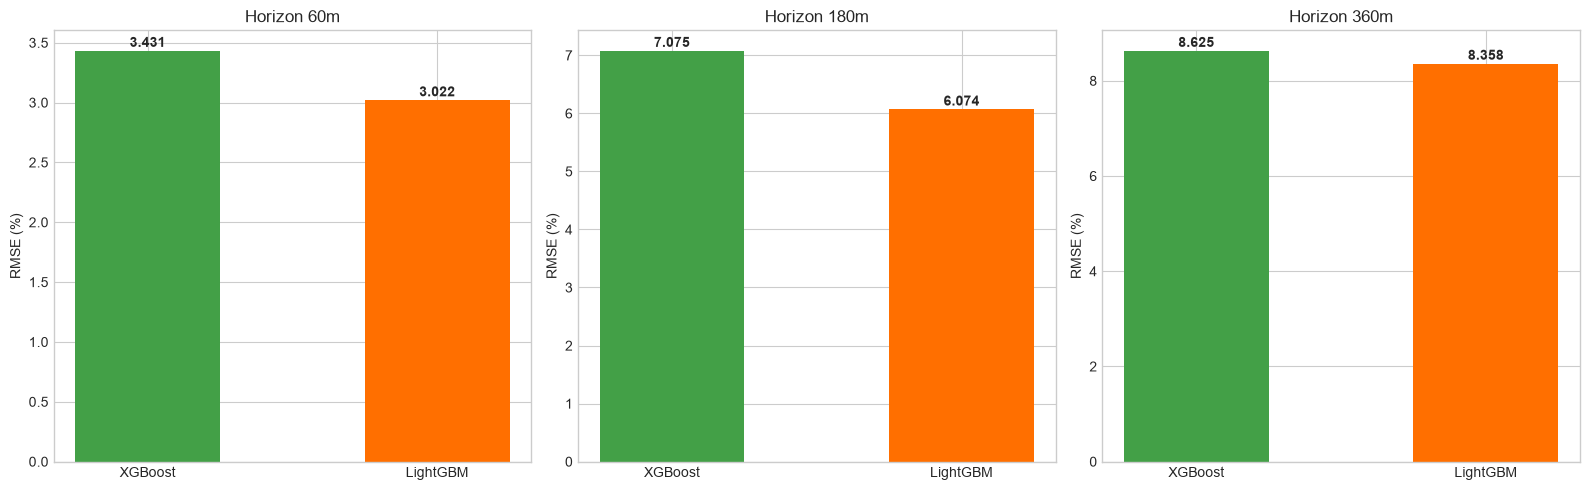

Lanjut ke 05r_evaluasi_model.ipynb


In [4]:
# -- CELL 6-7: Ringkasan & plot ------------------------------------
with open(f'{MOUT}/rf_metrics_all.json') as f: rf_results = json.load(f)
print(f'{"Horizon":<8}{"Model":<13}{"MAE":>8}{"RMSE":>8}{"R2":>8}{"MAPE":>8}')
for h in HORIZONS:
    for nama, res, key in [('RF', rf_results, 'test_metrics'), ('XGBoost', xgb_results, 'test_metrics'),
                           ('LightGBM', lgb_results, 'test_metrics'), ('Persistensi', rf_results, 'persistensi_metrics')]:
        m = res[h][key]; print(f'{h:<8}{nama:<13}{m["MAE"]:>8.3f}{m["RMSE"]:>8.3f}{m["R2"]:>8.3f}{m["MAPE"]:>8.2f}')
    print()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, h in zip(axes, HORIZONS):
    v = [xgb_results[h]['test_metrics']['RMSE'], lgb_results[h]['test_metrics']['RMSE']]
    bars = ax.bar(['XGBoost', 'LightGBM'], v, color=['#43A047', '#FF6F00'], width=0.5)
    for b, x in zip(bars, v): ax.text(b.get_x()+b.get_width()/2, x*1.01, f'{x:.3f}', ha='center', fontweight='bold')
    ax.set_title(f'Horizon {h}'); ax.set_ylabel('RMSE (%)')
plt.tight_layout(); plt.savefig(f'{OUT}/plot_xgb_lgb_rmse_revisi.png', dpi=150); plt.show()
print('Lanjut ke 05r_evaluasi_model.ipynb')